# Model and training

This notebook explains the data pipeline and the model, defines the training recipe (shared by both variants), and trains the **four runs**: variants A (frozen backbone) and B (last 4 ViT blocks fine-tuned with a 10× smaller LR) on Cityscapes and on NYUv2. These four runs are the baseline of the A/B comparison, not the final model (notebook 09). The training code itself is in `mtl_train.py`.

It requires the `data/` folder produced from `01_data.ipynb`. The trained checkpoints (`ckpt/<run>/final.pt`) are what `03_benchmarks.ipynb` evaluates.

## Setup

***NOTE:*** The DINOv2 and DPT code is used straight from the local repositories `./dinov2` and `./DPT`.

In [5]:
import os, sys
if os.path.basename(os.getcwd()) == "experiments":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

In [ ]:
from mtl_train import *   # mtl_common + the training code (critic, losses, optimizer, train_run)

configure()

print(f"Device: {device}")
print(f"torch: {torch.__version__}, GPU: {torch.cuda.get_device_name(0) if device.type == 'cuda' else 'none'}")
print(f"Data folder: {CFG['data_root']}")

## Configuration
One dictionary `CFG` holds every hyper-parameter; nothing else in the notebook hard-codes a number.

The training recipe is the same for both variants and both datasets. Each value has a source:

| Group | Value | Source |
|---|---|---|
| backbone | `dinov2_vits14`, layers `(2,5,8,11)` (0-indexed = blocks 3,6,9,12) | DINOv2 §7.4 (layers {3, 6, 9, 12} for ViT-S/B in the "lin. 4" and DPT setups); the same indices as DINOv2's DPT depth head (`hub/depthers.py`, `out_index["vit_small"]`) |
| decoder | 256 fusion channels, reassemble channels `(48,96,192,384)` = `embed_dim / 2^(3-i)`, readout "project" | DPT §3; DINOv2 `hub/depthers.py::_make_dinov2_dpt_depth_head` |
| loss | SiLog(λ=0.5) + CE + 0.4·aux CE + 0.1·WGAN critic, GP weight 100 | SwinMTL `trainMulti.py` (total = seg + depth + 0.1·generator term, GP weight 100) and `utils/criterion.py` (SiLog λ = 0.5). Auxiliary segmentation head: the idea and head design follow DPT §4.2, but DPT attaches it to the penultimate fusion output with weight 0.2; here it reads the deepest fused map with weight 0.4 (my choice) |
| aug. | photometric (brightness/contrast, gamma, HSV) + horizontal flip + random crop + patch mixing | SwinMTL `dataset/base_dataset.py` and `trainMulti.py::mixed_data` |
| aug. (scale) | random rescale s ∈ [1, 1.5], depth divided by s | my choice (SwinMTL has no scale augmentation); the range is tested by ablations AUG-A / AUG-B (notebook 07) |
| optim. | AdamW; poly decay with power 0.9 after the warm-up, floored at 1 % of the LR | AdamW: SwinMTL; poly-0.9: DPT §4.2 and SwinMTL §IV-A (SwinMTL's code instead ramps the LR up over the first half of training and down over the second; see the optimizer section below) |
| optim. (values) | head LR 1e-4, wd 1e-2, 1.5k linear warm-up | my choice: SwinMTL uses one LR schedule between 3e-5 and 5e-4, with wd 5e-2, for its whole model; DINOv2 does not publish the training hyper-parameters of its dense heads (§7.4 refers to the protocol of Li et al., 2022b) |
| variant B | last 4 blocks + final norm trainable, backbone LR = 0.1 × head LR, layer decay 0.9, backbone wd 0.05 | layer decay 0.9 and wd 0.05: SwinMTL's defaults (`--layer_decay 0.9`, `--weight_decay 5e-2`); 4 blocks and the 0.1 LR ratio: my choice (8 blocks after ablation E1) |
| depth range | Cityscapes 80 m, NYU 10 m | SwinMTL §IV-A ("80m for the Cityscapes dataset and 10m for the NYU Depth V2 dataset") |

**Dataset geometry.**
- Cityscapes is trained at a **base resolution of 512×1024**, which is SwinMTL Table I's resolution. Random crops of 448×896 are taken from it.
- Cityscapes uses three cameras: fx = 2256.47, 2262.52 or 2268.36 px at 2048 px width (2262.52 for 61 % of the train + val images). The depth ground truth uses each image's own fx and baseline (notebook 01). `fx_base` = 2262.52 / 2 is only the reference focal length used to rescale KITTI images in the zero-shot test.
- NYUv2 is trained at its native 480×640, with 476×630 crops.
- All crops are multiples of the 14-pixel patch.

In [4]:
# training hyper-parameters
for key, value in CFG.items():
    if key not in ["datasets", "crestereo", "zero_shot"]:
        print(f"{key}: {value}")

# dataset geometry and schedules
for name, dataset_cfg in CFG["datasets"].items():
    print(f"\n{name}: {dataset_cfg}")

data_root: /home/chrisjf/Documents/ml4cv/data
ckpt_root: /home/chrisjf/Documents/ml4cv/ckpt
results_root: /home/chrisjf/Documents/ml4cv/results
seed: 42
amp: True
amp_dtype: torch.bfloat16
num_workers: 8
backbone: dinov2_vits14
layers: (2, 5, 8, 11)
features: 256
post_channels: (48, 96, 192, 384)
variants: {'frozen': {'n_trainable_blocks': 0}, 'partial_ft': {'n_trainable_blocks': 4, 'backbone_lr_ratio': 0.1, 'layer_decay': 0.9, 'backbone_wd': 0.05, 'grad_ckpt': True}}
batch_size: 8
head_lr: 0.0001
head_wd: 0.01
warmup_iters: 1500
poly_power: 0.9
min_lr_ratio: 0.01
w_depth: 1.0
w_seg: 1.0
w_aux: 0.4
w_gen: 0.1
use_critic: True
critic_lr: 0.0001
critic_wd: 0.0001
gp_weight: 100.0
critic_log_depth: True
use_patch_mix: True
frame_pe: False
scale_aug: (1.0, 1.5)
photo_rng_fix: False
rotate_deg: 0.0
depth_param: linear
depth_head: regression
n_depth_bins: 256
log_every: 50
ckpt_every: 2000
val_every: 4000
val_images: 100
ms_scales: (0.5, 0.75, 1.0, 1.25, 1.5, 1.75)

cityscapes: {'num_classes

---
## Data pipeline used for training

### Label spaces

In [6]:
label_spaces = [
    ("Cityscapes", CS_NAMES),
    ("NYU40", NYU40_NAMES),
    ("ADE20K", ADE150_NAMES),
    ("VOC", VOC_NAMES),
    ("Pascal Context", PC59_NAMES),
]

for name, class_names in label_spaces:
    print(f"{name}: {len(class_names)} classes, e.g. {class_names[:6]}")

Cityscapes: 20 classes, e.g. ['road', 'sidewalk', 'building', 'wall', 'fence', 'pole']
NYU40: 40 classes, e.g. ['wall', 'floor', 'cabinet', 'bed', 'chair', 'sofa']
ADE20K: 150 classes, e.g. ['wall', 'building', 'sky', 'floor', 'tree', 'ceiling']
VOC: 21 classes, e.g. ['background', 'aeroplane', 'bicycle', 'bird', 'boat', 'bottle']
Pascal Context: 59 classes, e.g. ['aeroplane', 'bag', 'bed', 'bedclothes', 'bench', 'bicycle']


### Augmentation (the SwinMTL pipeline)

- `PHOTO_AUG` is SwinMTL's `basic_transform`: `RandomBrightnessContrast`, `RandomGamma`, `HueSaturationValue` (albumentations defaults, p = 0.5 each). It acts on the image only.
- `geometric_aug` applies the same geometric transform to image, depth and segmentation:
  1. **random rescale** s ∈ `CFG['scale_aug']` = [1, 1.5]. The image is resized bilinearly, and depth and segmentation with nearest neighbour, so invalid zeros and label ids are never blended. **Depth is divided by s**: enlarging the image by s is what the camera would see if the scene were s times closer (for a fixed focal length), so this keeps the metric depth geometrically consistent.
  2. **random crop** to the training crop size (SwinMTL `A.RandomCrop`).
  3. **horizontal flip** with p = 0.5 (SwinMTL `A.HorizontalFlip`).

SwinMTL uses photometric + flip + crop. Rescaling comes from the DPT/DINOv2 segmentation recipes; dividing depth by s keeps it valid for depth as well.

In [7]:
print(PHOTO_AUG)

Compose([
  RandomBrightnessContrast(p=0.5, brightness_by_max=True, brightness_limit=(-0.2, 0.2), contrast_limit=(-0.2, 0.2), ensure_safe_range=False),
  RandomGamma(p=0.5, gamma_limit=(80.0, 120.0)),
  HueSaturationValue(p=0.5, hue_shift_limit=(-20.0, 20.0), sat_shift_limit=(-30.0, 30.0), val_shift_limit=(-20.0, 20.0)),
], p=1.0, bbox_params=None, keypoint_params=None, additional_targets={}, is_check_shapes=True)


### Training / evaluation datasets

| Mode | Image | Depth | Seg | Notes |
|---|---|---|---|---|
| train | resized to the base resolution, then `geometric_aug` + `PHOTO_AUG` | `(1,h,w)` metres | `(h,w)` int64 | |
| eval | at base resolution, normalised | at **full resolution** | at **full resolution** | the evaluator decides at which resolution each protocol scores |

**Label spaces.**
- *Cityscapes*: `labelIds → trainId` through `CS_ID2TRAIN`, with void = 19. Like SwinMTL, the model is trained with 20 classes, void included (`num_classes=20` in `SwinMTL/configs/base_options.py`). This is what makes SwinMTL's own per-image mIoU computable; the standard 19-class mIoU simply ignores void.
- *NYU*: label 0 (unlabelled) → 255 (ignored); 1..40 → 0..39.

**`make_dataset`** is the single factory used by training and evaluation.

### Visual check of a training batch

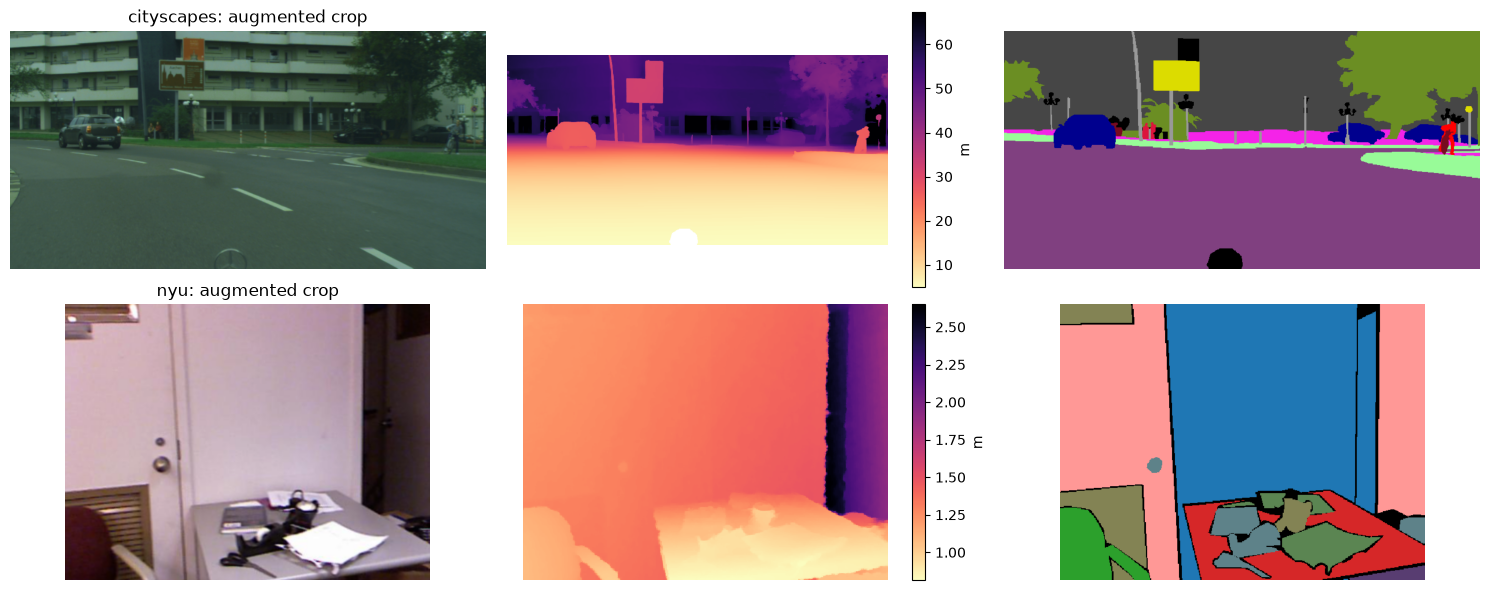

In [9]:
fig, axs = plt.subplots(2, 3)
fig.set_size_inches(15, 6)

for row, name in enumerate(["cityscapes", "nyu"]):
    sample = make_dataset(name, "train", True)[0]
    depth = sample["depth"][0].numpy()

    axs[row, 0].imshow(denormalize(sample["image"]))
    axs[row, 0].set_title(f"{name}: augmented crop")

    im = axs[row, 1].imshow(np.where(depth > 0, depth, np.nan), cmap="magma_r")
    fig.colorbar(im, ax=axs[row, 1], label="m")

    axs[row, 2].imshow(colorize_seg(sample["seg"].numpy(), PALETTES[name]))

    for ax in axs[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

---
## Model: `DinoDPT`

### Shape and parameter check

In [14]:
crop_h, crop_w = CFG["datasets"]["cityscapes"]["crop"]

for variant in CFG["variants"]:
    model = build_model("cityscapes", variant)
    model.to(device)
    model.train()

    stats = torchinfo.summary(model, verbose=0)   # parameter counts only
    total_params, trainable_params = stats.total_params / 1e6, stats.trainable_params / 1e6
    backbone_trainable = torchinfo.summary(model.backbone, verbose=0).trainable_params / 1e6

    # forward + backward on one training crop
    x = torch.randn(1, 3, crop_h, crop_w, device=device)
    with autocast():
        out = model(x)
    (out["depth"].float().mean() + out["seg"].float().mean()).backward()

    print(
        f"{variant}: total {total_params:.1f}M, trainable {trainable_params:.1f}M (backbone {backbone_trainable:.1f}M), "
        f"depth {tuple(out['depth'].shape)}, seg {tuple(out['seg'].shape)}, aux {tuple(out['aux'].shape)}"
    )
    del model, out

if device.type == "cuda":
    torch.cuda.empty_cache()

frozen: total 37.8M, trainable 15.8M (backbone 0.0M), depth (1, 1, 448, 896), seg (1, 20, 448, 896), aux (1, 20, 448, 896)


partial_ft: total 37.8M, trainable 22.9M (backbone 7.1M), depth (1, 1, 448, 896), seg (1, 20, 448, 896), aux (1, 20, 448, 896)


### The critic (WGAN-GP), ported from SwinMTL

*Code: `mtl_train.py` (`normal_init`, `Critic`, `critic_input`), moved there from this notebook on 2026-11-11 and imported in the setup cell.*

---
## Training recipe (shared by both variants)

### Loss functions and patch mixing

- `SiLogLoss` is ported from SwinMTL, with a numerical guard: the prediction is clamped at `min_depth` and the value under the square root at ≥ 1e-8.
- `mixed_data` is ported from `SwinMTL/trainMulti.py`, unchanged in logic.
- `gradient_penalty` is the WGAN-GP penalty, ported from `get_gradient` / `gradient_penalty`.

In [16]:
gt_example = torch.rand(2, 1, 8, 8) * 5 + 0.1
silog_value = SiLogLoss()(gt_example, gt_example)
assert silog_value < 1e-3
print(f"SiLog(gt, gt) = {silog_value.item()}")


SiLog(gt, gt) = 9.999999747378752e-05


### Optimizer and learning-rate schedule
`build_optimizer` creates AdamW parameter groups:

| Group | LR | Weight decay |
|---|---|---|
| decoder + heads (weights) | `head_lr` = 1e-4 | 1e-2 |
| decoder + heads (biases, norms) | `head_lr` | 0 |
| **variant B only**: ViT block i ∈ {8..11} (0-indexed) | `head_lr × 0.1 × 0.9^(11−i)` | 0.05 on weights; 0 on biases, norms and LayerScale γ |
| **variant B only**: final ViT norm | `head_lr × 0.1` | 0 |

So, with the 0-indexed numbering of the table and of the printed groups, block 11 (the last) gets 1e-5, block 10 9e-6, block 9 8.1e-6 and block 8 7.3e-6. The final model fine-tunes 8 blocks (ablation E1, notebooks 04/06), i.e. blocks 4–11 with the same rule, down to 1e-5 × 0.9⁷ ≈ 4.8e-6 for block 4. Following the usual fine-tuning practice, the pretrained layers move less than the new ones, and deeper (more task-specific) layers move more than earlier ones. This is the same idea as SwinMTL's layer-wise decay (`layer_decay=0.9`).

`build_scheduler` multiplies every group's LR by a linear warm-up over the first 1.5k iterations, then by a polynomial decay $(1 - t/T)^{0.9}$, where t and T count the iterations after the warm-up, floored at 1 % of the LR.
- The poly-0.9 decay follows DPT §4.2 ("a polynomial learning rate scheduler with decay factor 0.9") and SwinMTL §IV-A ("the learning rate follows a polynomial strategy with a decay factor of 0.9").
- SwinMTL's code (`trainMulti.py`) actually does something else: the LR *rises* from 3e-5 to 5e-4 along a 0.9-power curve during the first half of training and falls back during the second half. I follow the papers' description (short warm-up, then decay), not that code.

In [17]:
# parameter groups of variant B
model = build_model("nyu", "partial_ft", pretrained=False)
optimizer = build_optimizer(model, CFG["variants"]["partial_ft"])
for group in optimizer.param_groups:
    n_params = sum(p.numel() for p in group["params"]) / 1e6
    print(f"{group['name']}: lr={group['lr']:.2e}, wd={group['weight_decay']:.0e}, params={n_params:.2f}M")
del model, optimizer


head: lr=1.00e-04, wd=1e-02, params=15.75M
head_nd: lr=1.00e-04, wd=0e+00, params=0.01M
block8: lr=7.29e-06, wd=5e-02, params=1.77M
block8_nd: lr=7.29e-06, wd=0e+00, params=0.01M
block9: lr=8.10e-06, wd=5e-02, params=1.77M
block9_nd: lr=8.10e-06, wd=0e+00, params=0.01M
block10: lr=9.00e-06, wd=5e-02, params=1.77M
block10_nd: lr=9.00e-06, wd=0e+00, params=0.01M
block11: lr=1.00e-05, wd=5e-02, params=1.77M
block11_nd: lr=1.00e-05, wd=0e+00, params=0.01M
vit_norm: lr=1.00e-05, wd=0e+00, params=0.00M


### Training loop

After **ablation AB1.** `train_run` passes `batch["pe_window"]` to the model when the batch contains it. The datasets only add it when `CFG["frame_pe"]=True`, which is set in `05_ablation_frame_pe.ipynb` (ablation AB1) and, since frame PE was adopted for Cityscapes, in `09_final_model.ipynb` for the final Cityscapes model (the NYU final model has it off).

---
## Training the two variants

### Cityscapes, variant A (frozen backbone)

In [ ]:
hist_cs_A = train_run('cityscapes', 'frozen')

### Cityscapes, variant B (last 4 blocks fine-tuned with a small LR)

In [ ]:
hist_cs_B = train_run('cityscapes', 'partial_ft')

### NYUv2, variant A

In [ ]:
hist_nyu_A = train_run('nyu', 'frozen')

### NYUv2, variant B

In [ ]:
hist_nyu_B = train_run('nyu', 'partial_ft')

### Training curves

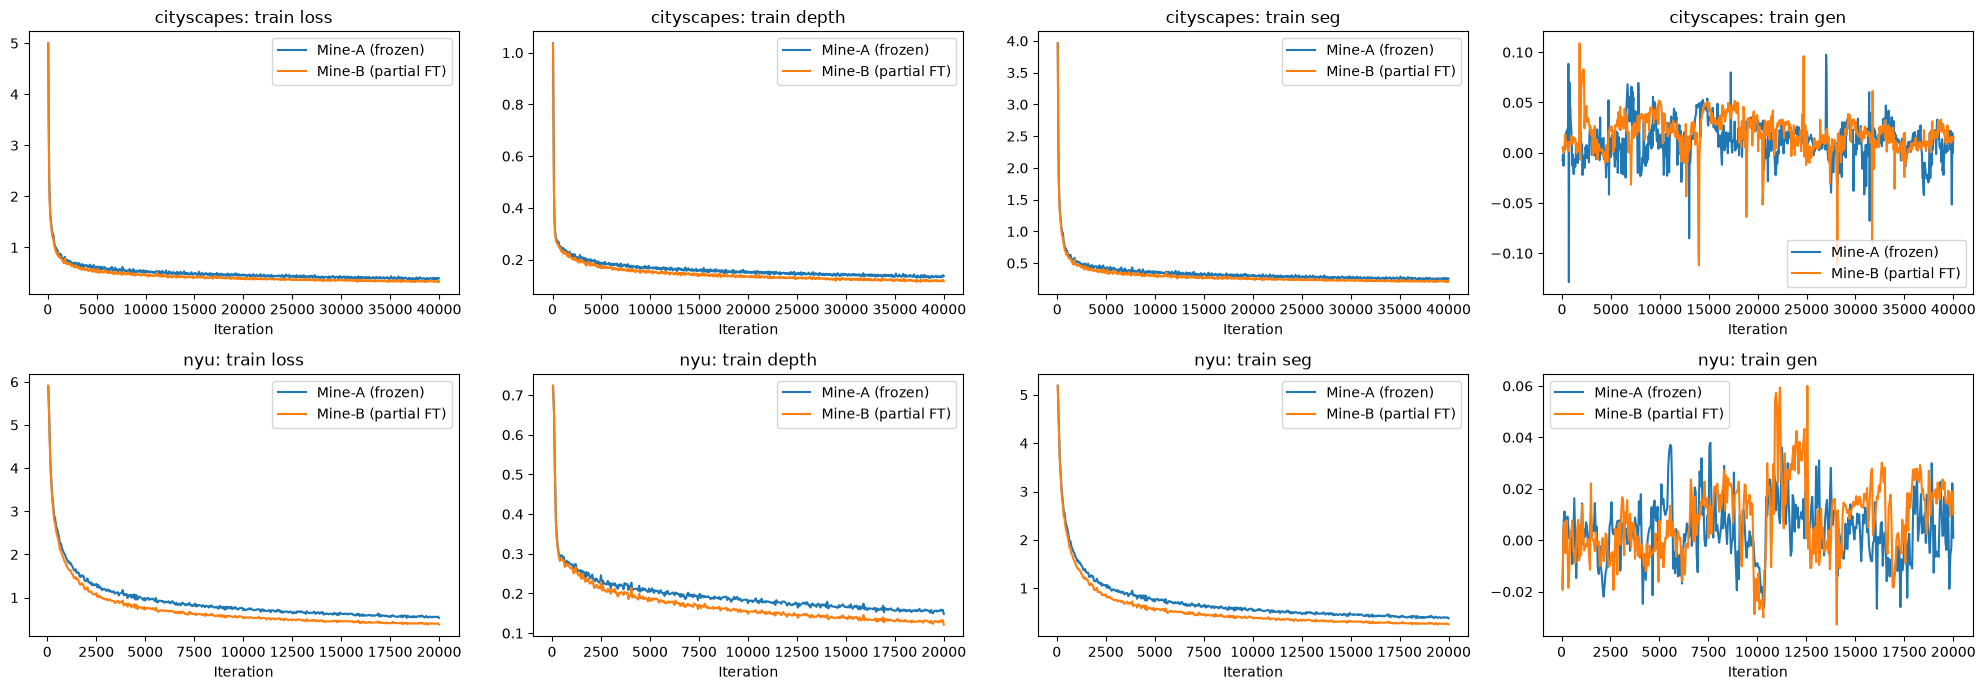

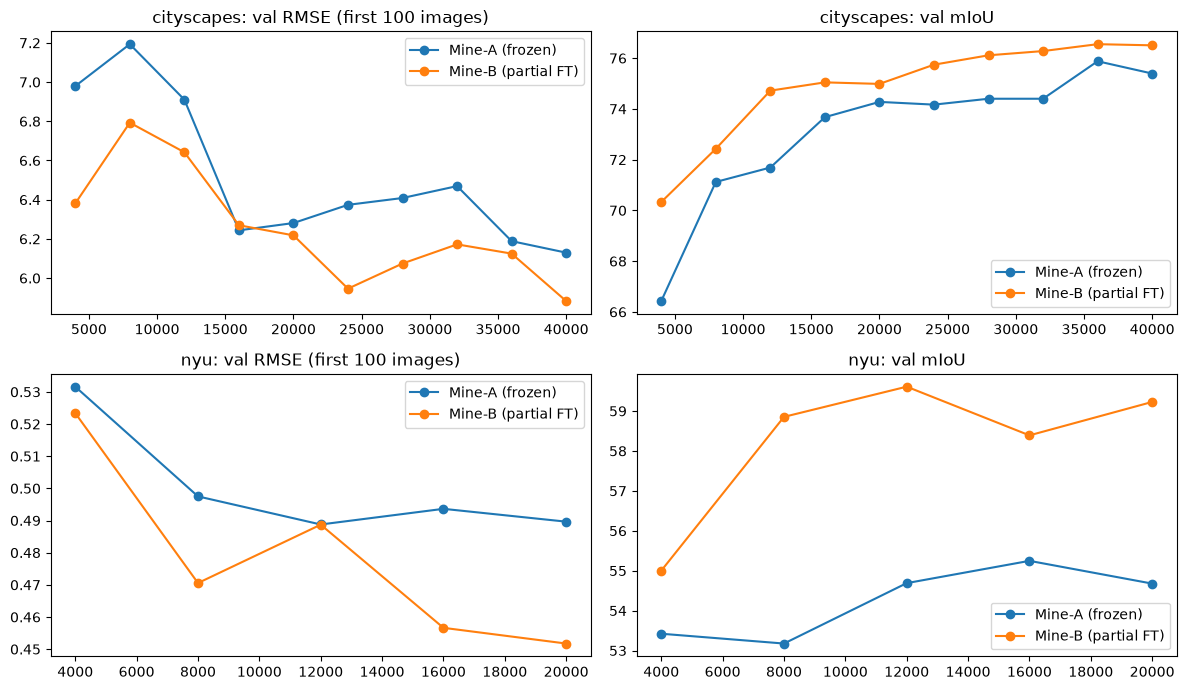

In [23]:
def plot_training_curves() -> None:
    """
    Training losses and quick-validation metrics of the four runs.
    """
    # train losses
    fig, axs = plt.subplots(2, 4)
    fig.set_size_inches(20, 7)

    for row, dataset in enumerate(["cityscapes", "nyu"]):
        for variant in CFG["variants"]:
            history = load_json(CFG["results_root"] / "train" / f"{run_name(dataset, variant)}.json")
            if not history:
                continue

            for col, key in enumerate(["loss", "depth", "seg", "gen"]):
                axs[row, col].plot(history["iter"], history[key], label=VARIANT_LABEL[variant])
                axs[row, col].set_title(f"{dataset}: train {key}")
                axs[row, col].set_xlabel("Iteration")

    for ax in axs.ravel():
        if ax.lines:
            ax.legend()

    plt.tight_layout()
    plt.show()

    # quick validation
    fig, axs = plt.subplots(2, 2)
    fig.set_size_inches(12, 7)

    for row, dataset in enumerate(["cityscapes", "nyu"]):
        for variant in CFG["variants"]:
            history = load_json(CFG["results_root"] / "train" / f"{run_name(dataset, variant)}.json")
            if not history or not history["val"]:
                continue

            iters = [v["iter"] for v in history["val"]]
            axs[row, 0].plot(iters, [v["rmse"] for v in history["val"]], "o-", label=VARIANT_LABEL[variant])
            axs[row, 1].plot(iters, [v["mIoU"] for v in history["val"]], "o-", label=VARIANT_LABEL[variant])

        axs[row, 0].set_title(f"{dataset}: val RMSE (first {CFG['val_images']} images)")
        axs[row, 1].set_title(f"{dataset}: val mIoU")
        for ax in axs[row]:
            if ax.lines:
                ax.legend()

    plt.tight_layout()
    plt.show()


plot_training_curves()